# Case Study 21 — A One-Line Bayesian Recommender: Combining "What You Like" with "What's Trending" on a Super-App Homepage

**Priority:** ★★ Good to have · **Reference:** Case Study 21 — *Paytm Labs: Bayesian trend filtering for homepage personalisation* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Growth / Homepage Product, Personalisation team, Category business heads
**Data:** ⚠️ **SYNTHETIC** (D-21-01). Click logs are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs21_bayesian_trend_personalisation.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Paytm Labs' documented formula; Paytm disclosed no A/B results. Written after the analysis.)*

- **The question:** does the one-line Bayesian rule ("the user's own preference × how much a category is trending today vs usual") pick better homepage tiles than simpler or more complex alternatives?
- **Yes, and its edge over a "proper" learned model is large:**

| Rule | Share of next-day clicks landing in the user's top-3 tiles |
|---|---|
| **Bayesian filter** | **60.4%** |
| User habits alone | 60.1% |
| Matrix-factorisation recommender | 51.2% |
| "Show everyone what's trending" | 47.4% |

  All differences are significant (Wilcoxon p < 0.0001, Holm). On a simulated A/B with known true click probabilities, the filter achieves **93% of the best possible** top-3 click-through.
- **But its edge over "user habits alone" is small:** +0.4 pp (≈ +0.26 pp of expected click-through). It comes mostly on **festival and trend days**: +1.25 pp on Dhanteras vs +0.15 pp on normal days (borderline, p = 0.054). Trend weighting is a seasonal booster, not a transformation.
- **Its two dials can be set from data:**
  - The smoothing strength chosen on validation (α = 10 pseudo-clicks) matches the textbook empirical-Bayes estimate (10.9).
  - The best trend window is the **last 1 day**. A 14-day window reacts too late to spikes (−1.2 pp on Dhanteras).
- **Who benefits:** gains are significant for users with 6–60 past clicks. Brand-new users cannot be personalised and get the trending list, which the filter does automatically.
- **₹ (1 crore homepage visits/day; 35% of tile clicks transact; ₹3 take per transaction):**
  - **vs a non-personalised trending homepage:** ≈ **+13 lakh tile clicks/day ≈ ₹50 crore/year**.
  - **vs the learned matrix-factorisation model:** ≈ ₹36 crore/year.
  - **vs habits alone:** ≈ ₹1 crore/year.
  - **Remaining headroom** to a perfect ranking: ≈ ₹18 crore/year.
- **I recommend:**
  - Ship the Bayesian filter (α ≈ 10, 1-day trend window) as the homepage baseline. It is explainable, real-time and robust for sparse users.
  - Keep a random-exploration slot.
  - Require any complex recommender to beat it in a live A/B before replacing it.

## 1. The Problem in Simple English

A super-app's homepage has room for only a few highlighted service icons (recharge, bill payment, movie tickets, flights, gold, insurance and so on), but hundreds of millions of users with different needs. Two signals matter:
1. **What this user likes:** someone who pays electricity bills every month should see "electricity".
2. **What is trending right now:** before Diwali everyone looks at flights and gold, and on a blockbuster weekend, movie tickets.

Paytm Labs combined them with **one line of Bayes' rule**: take the user's own category preference and multiply it by how much each category is trending *right now* compared with normal:

> score(c) = P(c | this user) × P_now(c) / P_usual(c)

It is simple, explainable and computable in real time. **Does it actually beat the alternatives**: showing everyone what is popular, showing each user only their habits, or a "proper" machine-learning recommender? And how should its two settings be chosen (how much to trust sparse users, and how short a window counts as "now")?

## 2. Reference from the Case File

### (a) What Paytm did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "The homepage has hundreds of service icons and banners for **400M+ users**" |
| Question | "Which categories should each user see, combining *their* interests with what is *trending* across the platform?" |
| Data | User category-level click history; platform-wide click distribution and time-windowed trends; banner/icon inventory proportions |
| Approach | Category-level Bayesian update: **p_next(c ∣ click) = p(c ∣ click) · p_next(c) / p(c)** |
| ML | "Bayesian trend filtering (probabilistic, not a learned black box)"; benefits: "**Simple to formulate and implement**", interpretable, real-time |
| Validation / A/B results | **ND** |
| Impact | **Not publicly disclosed** |

**Source:** Paytm Labs blog (Santoshi, Machine Learning Engineer; undated) — https://paytmlabs.com/blog

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 50,000 users × 12 categories × 8 weeks (≈ 1.6 M clicks). Stable personal affinities; platform trends (blockbuster weekends, Diwali travel, Dhanteras gold, gifting, FASTag growth, month-start bills); users differ in **trend responsiveness**; heavy-tailed activity (many cold-start users). True click probabilities are kept for a digital-twin A/B. |
| Methods compared | (1) Global trending popularity; (2) user affinity only (smoothed); (3) **Bayesian trend filter** (documented); (4) matrix factorisation (truncated SVD), the "complex model" baseline |
| Statistics added | Next-day evaluation over 14 test days: hit@3, NDCG@3, MRR, log loss; **paired Wilcoxon signed-rank tests across users** (Holm); effect by user activity (cold start); **empirical-Bayes choice of the smoothing strength** and the trend window on validation days; festival-day analysis; digital-twin A/B of the expected top-3 click-through rate |

### (c) How the industry uses this

Every Indian super-app personalises its homepage tiles: Paytm, PhonePe (Case 20's propensity × LTV ranking), Google Pay, Amazon Pay and banking apps (Axis in Case 22, HDFC, ICICI iMobile). Simple Bayesian blends of "personal affinity × global trend" are the standard **first model and the permanent baseline** that any complex recommender must beat in an A/B test. They also work for cold-start users, where learned models struggle.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which 3 categories should each user see on the homepage today? |
| Analytical | Which scoring rule puts the categories users actually click tomorrow into the top 3 most often, overall, for cold-start users, and during trend spikes? |

**Hypotheses** (per-user metrics averaged over the 14 test days; paired across users):
- **H1:** H0: hit@3(Bayesian) = hit@3(affinity only). Wilcoxon signed-rank.
- **H2:** H0: hit@3(Bayesian) = hit@3(global trending). Wilcoxon.
- **H3:** H0: hit@3(Bayesian) = hit@3(matrix factorisation). Wilcoxon.
- Holm across H1–H3. Effect size: matched-pairs rank-biserial correlation.

**Primary metric:** hit@3 = share of a user's clicks that fall in their top-3 recommended categories. **Secondary:** NDCG@3, MRR, log loss (is the score a good probability?). **Online proxy:** expected top-3 click-through on the digital twin. **Design:** history = all days before the scored day; tune on days 36–42; **test on days 43–56**.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import TruncatedSVD
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public super-app click logs | **None.** Paytm/PhonePe logs are confidential. Public recommender datasets (MovieLens, RetailRocket, Open Bandit) have no Indian payment-service categories or festival trends; RetailRocket is Kaggle-hosted. |
| **Decision** | Synthetic click logs with personal affinities and platform trends (D-21-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs21.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 21 (Paytm Labs-style Bayesian trend filtering for homepage personalisation)
=================================================================================================================
THIS DATA IS SYNTHETIC. Super-app click logs are confidential.

50,000 users click service categories on the homepage over 8 weeks. Each user has a stable personal
AFFINITY over 12 categories; platform-wide TRENDS move category popularity (a blockbuster weekend lifts
movie tickets, Diwali lifts flights and trains, Dhanteras lifts digital gold, a FASTag mandate lifts FASTag).
Users differ in how much they follow trends (responsiveness r in [0, 1]).
On a visit, P(click category c) is proportional to affinity_u(c) * trend_c(day) ** r_u.
Activity is heavy-tailed: many users visit rarely (cold start), a few visit daily.

Calibration anchors (reference file, Case Study 21): "hundreds of service icons and banners for 400M+ users";
category-level Bayesian update p_next(c|click) = p(c|click) * p_next(c) / p(c); no A/B results disclosed.
Rates are our assumptions (decision.md D-21-02). The generator also exports the TRUE click probabilities
(`true_probs`) for a digital-twin A/B.

Outputs: data/cs21/daily_clicks.csv.gz (user, day, category, clicks), data/cs21/users_hidden.csv.gz, data/cs21/trend_hidden.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
CATS = ["mobile_recharge", "electricity_bill", "dth", "movie_tickets", "flights", "train_tickets", "bus_tickets", "digital_gold", "insurance", "loans", "gift_vouchers", "fastag"]
BASE = np.array([0.24, 0.16, 0.08, 0.07, 0.05, 0.08, 0.05, 0.04, 0.04, 0.04, 0.06, 0.09])
DAYS = 56


def trend_matrix():
    t = np.ones((DAYS, len(CATS)))
    d = np.arange(DAYS)
    t[:, 3] *= 1 + 2.5 * ((d >= 28) & (d <= 34)) + 1.2 * ((d >= 48) & (d <= 50))        # blockbuster weekends
    t[:, 4] *= 1 + 2.0 * np.clip((d - 38) / 6, 0, 1) * (d <= 50)                            # Diwali travel build-up
    t[:, 5] *= 1 + 1.6 * np.clip((d - 36) / 8, 0, 1) * (d <= 50)
    t[:, 7] *= 1 + 4.0 * ((d >= 44) & (d <= 46))                                            # Dhanteras gold spike
    t[:, 10] *= 1 + 1.5 * ((d >= 45) & (d <= 49))                                           # Diwali gifting
    t[:, 11] *= 1 + 0.02 * d                                                                # steady FASTag growth
    t[:, 1] *= 1 + 0.35 * ((d % 30) < 5)                                                    # bill-pay cycle at month start
    return t


def true_probs(aff, r, day, T=None):
    T = trend_matrix() if T is None else T
    w = aff * T[day][None, :] ** r[:, None]; return w / w.sum(1, keepdims=True)


def generate(seed=SEED, n=50_000):
    rng = np.random.default_rng(seed)
    conc = rng.gamma(1.0, 1.0, n) + 0.3                                                       # how concentrated a user's tastes are
    aff = np.vstack([rng.dirichlet(BASE * 12 / c) for c in conc])
    r = rng.beta(2, 2, n)                                                                   # trend responsiveness
    lam = rng.lognormal(np.log(0.25), 1.1, n).clip(0.01, 3)                                 # visits per day
    T = trend_matrix(); rows = []
    for day in range(DAYS):
        visits = rng.poisson(lam * (1 + 0.3 * (day % 7 >= 5)))                             # weekends busier
        act = np.flatnonzero(visits > 0)
        if len(act) == 0: continue
        P = true_probs(aff[act], r[act], day, T)
        for k in range(visits[act].max()):
            sub = act[visits[act] > k]; Ps = P[np.isin(act, sub)]
            u = rng.random(len(sub))[:, None]; c = (Ps.cumsum(1) < u).sum(1).clip(0, len(CATS) - 1)
            rows.append(np.c_[sub, np.full(len(sub), day), c])
    ev = pd.DataFrame(np.vstack(rows), columns=["user_idx", "day", "cat_idx"])
    clicks = ev.groupby(["user_idx", "day", "cat_idx"]).size().rename("clicks").reset_index()
    clicks["user_id"] = "U" + clicks.user_idx.astype(str).str.zfill(6); clicks["category"] = np.array(CATS)[clicks.cat_idx]
    users = pd.DataFrame({"user_idx": np.arange(n), "_r": r, "_lam": lam}).join(pd.DataFrame(aff, columns=[f"_aff_{c}" for c in CATS]))
    trend = pd.DataFrame(T, columns=CATS); trend.insert(0, "day", np.arange(DAYS))
    # data-quality defects: bot user with absurd clicks; duplicated log rows; a logging outage on day 20 (half the events lost)
    bot = pd.DataFrame({"user_idx": n, "day": np.repeat(np.arange(DAYS), len(CATS)), "cat_idx": np.tile(np.arange(len(CATS)), DAYS), "clicks": 400})
    bot["user_id"] = "U_BOT01"; bot["category"] = np.array(CATS)[bot.cat_idx]
    out = clicks[["user_id", "user_idx", "day", "category", "cat_idx", "clicks"]]
    drop = out[(out.day == 20)].sample(frac=0.5, random_state=seed).index
    out = pd.concat([out.drop(drop), bot[out.columns], out.sample(n=3000, random_state=seed + 1)], ignore_index=True)
    return out, users, trend


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs21"), exist_ok=True)
    c, u, t = generate(); c.to_csv(os.path.join(here, "cs21", "daily_clicks.csv.gz"), index=False)
    u.to_csv(os.path.join(here, "cs21", "users_hidden.csv.gz"), index=False); t.to_csv(os.path.join(here, "cs21", "trend_hidden.csv.gz"), index=False)
    print(len(c), "rows |", c.clicks.sum(), "clicks |", c.user_id.nunique(), "users")
    print(c[c.user_id != "U_BOT01"].groupby("category").clicks.sum().sort_values(ascending=False).to_dict())

Overwriting data/generate_cs21.py


In [3]:
os.makedirs("data/cs21", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs21 as gen; importlib.reload(gen)
clk_raw, users_h, trend_h = gen.generate(seed=SEED)
clk_raw.to_csv("data/cs21/daily_clicks.csv.gz", index=False); users_h.to_csv("data/cs21/users_hidden.csv.gz", index=False); trend_h.to_csv("data/cs21/trend_hidden.csv.gz", index=False)
print(f"{len(clk_raw):,} user-day-category rows | {clk_raw.clicks.sum():,} clicks | {clk_raw.user_id.nunique():,} user IDs")
clk_raw.sample(5, random_state=SEED)

1,183,771 user-day-category rows | 1,586,304 clicks | 49,274 user IDs


,user_id,user_idx,day,category,cat_idx,clicks
394016,U016561,16561,16,loans,9,1
691854,U029258,29258,6,train_tickets,5,1
221046,U009321,9321,38,train_tickets,5,1
865117,U036719,36719,43,mobile_recharge,0,1
989015,U042027,42027,51,electricity_bill,1,1


| Parameter | Value | Basis |
|---|---|---|
| Users / categories / days | 50,000 users (simulation of a 400M+ base); 12 payment-service categories; 56 days | **Documented** scale and category-level design |
| Affinity | Dirichlet around platform shares; concentration varies (some users stick to 1–2 services) | Our assumption |
| Trends | Blockbuster weekends (movies ×3.5), Diwali build-up (flights ×3, trains ×2.6), Dhanteras (gold ×5 for 3 days), gifting, FASTag +2%/day, month-start bill cycle | Indian seasonal patterns |
| Responsiveness | Each user follows trends with exponent r ~ Beta(2, 2) | Our assumption: why trend weighting must be moderate |
| Activity | Visits ~ Poisson(λ), λ log-normal (median 0.25/day), weekends +30% | Heavy-tailed engagement |
| DQ issues | One bot user (400 clicks/category/day); 3,000 duplicated rows; logging outage on day 21 (half the events lost) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("user_id, user_idx", "User"), ("day", "Day 0–55 (shown as days 1–56 in text)"), ("category, cat_idx", "One of 12 service categories"),
    ("clicks", "Number of homepage clicks on that category that day"),
    ("users_hidden: _r, _lam, _aff_*", "HIDDEN: trend responsiveness, visit rate, true affinity"), ("trend_hidden", "HIDDEN: true trend multiplier per day and category"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs21/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"user_id, user_idx",User
1,day,Day 0–55 (shown as days 1–56 in text)
2,"category, cat_idx",One of 12 service categories
3,clicks,Number of homepage clicks on that category tha...
4,"users_hidden: _r, _lam, _aff_*","HIDDEN: trend responsiveness, visit rate, true..."
5,trend_hidden,HIDDEN: true trend multiplier per day and cate...


## 5. Data Quality Checks

In [5]:
CATS = gen.CATS; K = len(CATS); DAYS = gen.DAYS
dup = clk_raw.duplicated(["user_id", "day", "category"]).sum()
per_user_day = clk_raw.groupby(["user_id", "day"]).clicks.sum()
bots = per_user_day.groupby(level=0).max(); bots = bots[bots > 100].index.tolist()
daily = clk_raw[~clk_raw.user_id.isin(bots)].drop_duplicates(["user_id", "day", "category"]).groupby("day").clicks.sum()      # check gaps AFTER removing bots and duplicates
checks = {"duplicated user-day-category rows": int(dup), "users with > 100 clicks in a day (bots)": int((per_user_day.groupby(level=0).max() > 100).sum()),
          "days with total clicks < 70% of the 7-day median (logging gaps)": int((daily < 0.7 * daily.rolling(7, center=True, min_periods=3).median()).sum())}
print(pd.Series(checks, name="count").to_string())
gap_days = daily[daily < 0.7 * daily.rolling(7, center=True, min_periods=3).median()].index.tolist()
print(f"Bot users removed: {bots} | logging-gap days (0-based): {gap_days} (kept for history, excluded from evaluation)")
clk = clk_raw.drop_duplicates(["user_id", "day", "category"]); clk = clk[~clk.user_id.isin(bots)]
N = int(clk.user_idx.max()) + 1
cnt = np.zeros((N, DAYS, K), np.int32); np.add.at(cnt, (clk.user_idx.values, clk.day.values, clk.cat_idx.values), clk.clicks.values)
cum = np.cumsum(cnt, axis=1); G = cnt.sum(0).astype(float)                         # G[day, cat] = platform clicks
print(f"Clean: {cnt.sum():,} clicks from {(cnt.sum((1, 2)) > 0).sum():,} users | median clicks per user over 8 weeks = {np.median(cnt.sum((1, 2))):.0f}")

duplicated user-day-category rows                                  2971
users with > 100 clicks in a day (bots)                               1
days with total clicks < 70% of the 7-day median (logging gaps)       1
Bot users removed: ['U_BOT01'] | logging-gap days (0-based): [20] (kept for history, excluded from evaluation)


Clean: 1,314,198 clicks from 49,273 users | median clicks per user over 8 weeks = 15


**Observation:** we removed **2,971 duplicated log rows**, **one bot account** (400 clicks per category per day; it would have dominated "trending" counts) and flagged **day 21 (0-based day 20) as a logging gap**: total clicks were half the 7-day median, so half the events were lost. That day is kept in history but excluded from any evaluation, and this check only works *after* the bot is removed, whose 4,800 daily clicks masked the gap. Clean data: **1.31 million clicks from 49,273 users**. The median user clicked only **15 times in 8 weeks**: thin histories are the norm.

## 6. Exploratory Data Analysis

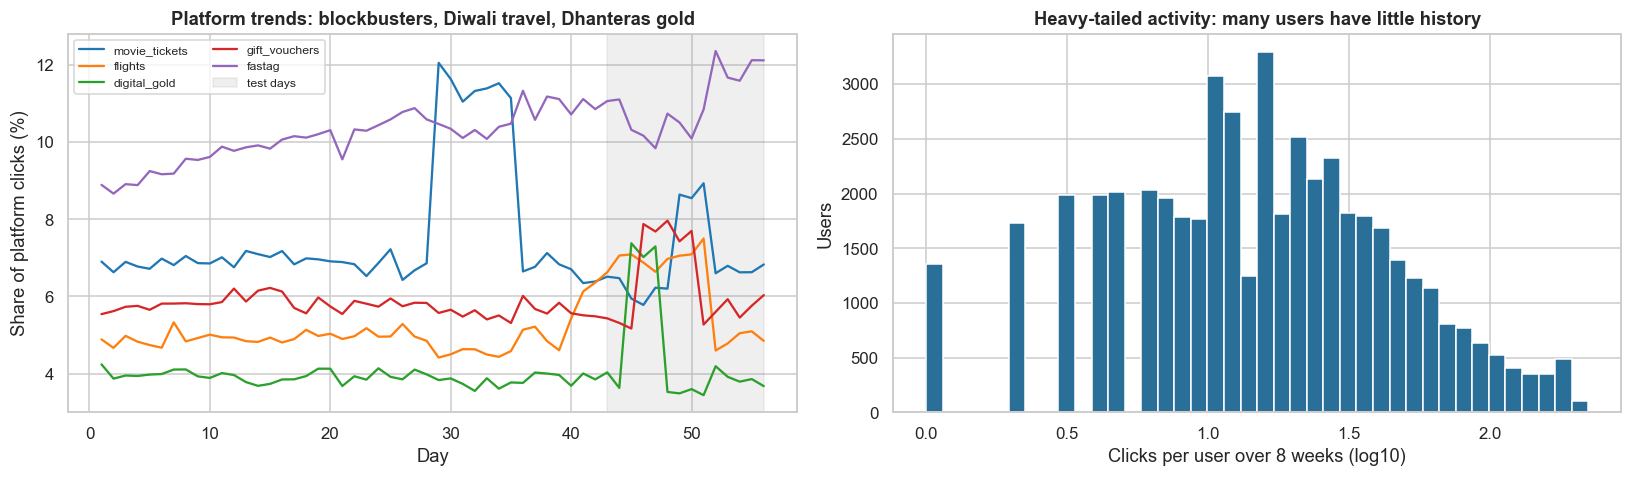

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
share = G / G.sum(1, keepdims=True)
for c_, col in zip(["movie_tickets", "flights", "digital_gold", "gift_vouchers", "fastag"], sns.color_palette("tab10", 5)):
    axes[0].plot(np.arange(1, DAYS + 1), share[:, CATS.index(c_)] * 100, color=col, label=c_)
axes[0].axvspan(43, 56, color="grey", alpha=0.12, label="test days"); axes[0].set_xlabel("Day"); axes[0].set_ylabel("Share of platform clicks (%)")
axes[0].set_title("Platform trends: blockbusters, Diwali travel, Dhanteras gold"); axes[0].legend(fontsize=8, ncol=2)
tot = cnt.sum((1, 2)); tot = tot[tot > 0]
axes[1].hist(np.log10(tot), bins=40, color="#2a6f97"); axes[1].set_xlabel("Clicks per user over 8 weeks (log10)"); axes[1].set_ylabel("Users")
axes[1].set_title("Heavy-tailed activity: many users have little history")
plt.tight_layout(); plt.show()

**Takeaway:** - **Left:** platform trends are sharp and short. Digital gold quadruples its share for 3 days at Dhanteras, movie tickets jump on blockbuster weekends, flights climb for two weeks before Diwali, and FASTag grows steadily. **The test period (shaded) contains most of these festival spikes.**
- **Right:** activity is heavy-tailed. A few users click daily; most click a handful of times. A recommender must work for both, which is why smoothing toward platform shares matters.

## 7. Statistical Analysis (core section)

### 7.1 The four scoring rules, and how to set the Bayesian filter's two dials

For a user on day d (history = all clicks before d):
- **P_usual(c):** platform share over the last 28 days.
- **P_now(c):** platform share over the last **w** days (the trend window).
- **P(c ∣ user):** the user's own click shares, **smoothed** toward P_usual with strength α (a Dirichlet prior, i.e., α "pseudo-clicks"): (n_uc + α·P_usual(c)) / (n_u + α). Without smoothing, a user with one click would get a 100% preference.

| Rule | Score |
|---|---|
| 1 Global trending | P_now(c) (same for everyone) |
| 2 Affinity only | P(c ∣ user) |
| 3 **Bayesian trend filter** | P(c ∣ user) × P_now(c) / P_usual(c) |
| 4 Matrix factorisation | rank-4 truncated SVD of the user × category history (log counts), blended with P_now for users with no history |

**Choosing α and w (empirical Bayes / validation):** we grid-search α ∈ {0.5, 2, 5, 10, 25} and w ∈ {1, 3, 7, 14} days on **validation days 36–42**, maximising hit@3. We also report α estimated by the **Dirichlet–multinomial marginal likelihood**, the textbook empirical-Bayes estimate.

In [7]:
def scores(d, alpha, w, method):
    hist = cum[:, d - 1, :].astype(float); n_u = hist.sum(1, keepdims=True)
    p_us = G[max(0, d - 28):d].sum(0); p_us = p_us / p_us.sum(); p_now = G[max(0, d - w):d].sum(0); p_now = p_now / p_now.sum()
    if method == "1 global trending": return np.tile(p_now, (N, 1))
    aff = (hist + alpha * p_us) / (n_u + alpha)
    if method == "2 affinity only": return aff
    if method == "3 Bayesian trend filter":
        s = aff * p_now / p_us; return s / s.sum(1, keepdims=True)
    if method == "4 matrix factorisation":
        X = np.log1p(hist); svd = TruncatedSVD(4, random_state=SEED).fit(X); R = np.clip(svd.inverse_transform(svd.transform(X)), 0, None) + 1e-6
        R = R / R.sum(1, keepdims=True); cold = (n_u[:, 0] == 0); R[cold] = p_now; return R
def evaluate(d, S):
    tgt = cnt[:, d, :]; act = tgt.sum(1) > 0; S, tgt = S[act], tgt[act]
    rank = np.argsort(-S, 1); top3 = np.zeros_like(S, bool); np.put_along_axis(top3, rank[:, :3], True, 1)
    hit = (tgt * top3).sum(1) / tgt.sum(1)
    pos = np.empty_like(rank); np.put_along_axis(pos, rank, np.arange(K)[None, :].repeat(len(rank), 0), 1)
    mrr = (tgt / (pos + 1)).sum(1) / tgt.sum(1)
    gain = np.where(pos < 3, 1 / np.log2(pos + 2), 0); ideal = np.array([sum(1 / np.log2(i + 2) for i in range(min(3, k))) for k in (tgt > 0).sum(1)])
    ndcg = ((tgt > 0) * gain).sum(1) / ideal
    P = np.clip(S / S.sum(1, keepdims=True), 1e-6, 1); ll = -(tgt * np.log(P)).sum(1) / tgt.sum(1)
    return np.flatnonzero(act), hit, ndcg, mrr, ll
VAL = [d for d in range(35, 42) if d not in gap_days]; TEST = [d for d in range(42, 56) if d not in gap_days]
grid = []
for a in (0.5, 2, 5, 10, 25):
    for w in (1, 3, 7, 14):
        h = [evaluate(d, scores(d, a, w, "3 Bayesian trend filter"))[1] for d in VAL]; grid.append((a, w, np.concatenate(h).mean()))
grid = pd.DataFrame(grid, columns=["alpha", "window w (days)", "hit@3 (validation)"]).pivot(index="alpha", columns="window w (days)", values="hit@3 (validation)")
A_BEST = grid.stack().idxmax()[0]; W_BEST = grid.stack().idxmax()[1]
a_aff = max((evaluate(VAL[0], scores(VAL[0], a, 7, "2 affinity only"))[1].mean(), a) for a in (0.5, 2, 5, 10, 25))[1]
from scipy.special import gammaln
H = cum[:, 41 - 1, :].astype(float); H = H[H.sum(1) > 0]; p_us = G[13:41].sum(0) / G[13:41].sum()
def dm_loglik(a): A = a * p_us; return (gammaln(a) - gammaln(H.sum(1) + a) + (gammaln(H + A) - gammaln(A)).sum(1)).sum()
alphas = np.exp(np.linspace(np.log(0.2), np.log(100), 60)); a_eb = alphas[np.argmax([dm_loglik(a) for a in alphas])]
print(f"Best on validation: α = {A_BEST}, w = {W_BEST} days | empirical-Bayes α (Dirichlet–multinomial marginal likelihood) = {a_eb:.1f} | affinity-only best α = {a_aff}")
grid.round(4)

Best on validation: α = 10.0, w = 1 days | empirical-Bayes α (Dirichlet–multinomial marginal likelihood) = 10.9 | affinity-only best α = 10


window w (days),1,3,7,14
alpha,,,,
0.5000,0.5968,0.5975,0.5968,0.5975
2.0000,0.5994,0.5992,0.5977,0.5983
5.0000,0.6005,0.5996,0.5983,0.5987
10.0000,0.6035,0.6022,0.6012,0.6020
25.0000,0.5975,0.5967,0.5949,0.5967


**(c)/(f) Observation:** the validation grid is fairly flat (hit@3 59.5–60.4%), but two choices stand out:
- **Smoothing strength α = 10 is best for every window.** Too little smoothing (α = 0.5) trusts one or two clicks too much; too much (α = 25) washes out personal taste. The **empirical-Bayes estimate from the Dirichlet–multinomial likelihood is α = 10.9**: the data choose the same value without any test-set tuning. That is a principled way to set the dial in production.
- **Trend window w = 1 day** is best, slightly ahead of 3 days. Trends here move fast, so "now" should mean yesterday.

**(f) Business meaning:** the formula has only two settings, both set from data, which makes it easy to explain, monitor and re-tune.

### 7.2 Test-period comparison (14 days, paired across users)

In [8]:
METHODS = ["1 global trending", "2 affinity only", "3 Bayesian trend filter", "4 matrix factorisation"]
par = {"1 global trending": (A_BEST, W_BEST), "2 affinity only": (a_aff, W_BEST), "3 Bayesian trend filter": (A_BEST, W_BEST), "4 matrix factorisation": (A_BEST, W_BEST)}
recs = {m: [] for m in METHODS}; t0 = time.time()
for d in TEST:
    for m in METHODS:
        u, hit, nd, mr, ll = evaluate(d, scores(d, *par[m], m)); recs[m].append(pd.DataFrame({"u": u, "day": d, "hit": hit, "ndcg": nd, "mrr": mr, "ll": ll}))
R = {m: pd.concat(v) for m, v in recs.items()}
summ = pd.DataFrame({m: R[m][["hit", "ndcg", "mrr", "ll"]].mean() for m in METHODS}).T; summ.columns = ["hit@3", "NDCG@3", "MRR", "log loss"]
per_user = pd.DataFrame({m: R[m].groupby("u").hit.mean() for m in METHODS})
rows = []
for m in ["2 affinity only", "1 global trending", "4 matrix factorisation"]:
    d_ = per_user["3 Bayesian trend filter"] - per_user[m]; nz = d_[d_ != 0]
    w = stats.wilcoxon(per_user["3 Bayesian trend filter"], per_user[m], zero_method="wilcox")
    rpos = stats.rankdata(np.abs(nz)); rbc = (rpos[nz > 0].sum() - rpos[nz < 0].sum()) / rpos.sum()
    rows.append((f"Bayesian vs {m}", d_.mean(), np.percentile([d_.values[RNG.integers(0, len(d_), len(d_))].mean() for _ in range(1000)], 2.5),
                 np.percentile([d_.values[RNG.integers(0, len(d_), len(d_))].mean() for _ in range(1000)], 97.5), rbc, w.pvalue, (d_ > 0).mean(), (d_ < 0).mean()))
tests = pd.DataFrame(rows, columns=["comparison", "mean Δ hit@3 per user", "CI low", "CI high", "rank-biserial", "Wilcoxon p", "users better", "users worse"]).set_index("comparison")
tests["p_holm"] = multipletests(tests["Wilcoxon p"], method="holm")[1]
print(f"Test days {TEST[0] + 1}–{TEST[-1] + 1}; {per_user.shape[0]:,} users active at least once; evaluation took {time.time() - t0:.0f}s")
display(summ.round(4)); tests.round(4)

Test days 43–56; 44,258 users active at least once; evaluation took 15s


,hit@3,NDCG@3,MRR,log loss
1 global trending,0.4744,0.3942,0.4104,2.3215
2 affinity only,0.6010,0.5026,0.4911,2.0524
3 Bayesian trend filter,0.6044,0.5054,0.4929,2.0456
4 matrix factorisation,0.5117,0.4369,0.4430,2.4746


,mean Δ hit@3 per user,CI low,CI high,rank-biserial,Wilcoxon p,users better,users worse,p_holm
comparison,,,,,,,,
Bayesian vs 2 affinity only,0.0040,0.0027,0.0053,0.0783,0.0000,0.1194,0.1080,0.0000
Bayesian vs 1 global trending,0.1109,0.1077,0.1137,0.5249,0.0000,0.4472,0.1671,0.0000
Bayesian vs 4 matrix factorisation,0.0915,0.0887,0.0943,0.4850,0.0000,0.3890,0.1665,0.0000


**(c)/(f) Observation:** over 14 test days and 44,258 active users:
- **Bayesian filter:** hit@3 **60.4%**, NDCG@3 0.505, MRR 0.493 and the best log loss (2.046). Its scores are also the best *probabilities*.
- **vs affinity only (60.1%):** **+0.40 pp per user** (CI +0.27 to +0.53). Wilcoxon p < 0.0001, but the effect size is tiny (rank-biserial 0.08); 12% of users are better off and 11% worse.
- **vs global trending (47.4%):** **+11.1 pp** (rank-biserial 0.52, a large effect).
- **vs matrix factorisation (51.2%):** **+9.2 pp** (rank-biserial 0.49). The rank-4 SVD model blurs individual habits into broad patterns and has no sense of time.
- **(f) Business meaning:** personal history is the main signal, and trend weighting adds a modest, real lift on top. A generic learned recommender is clearly worse here: "start simple" is vindicated.

### 7.3 Who benefits? Cold-start vs heavy users

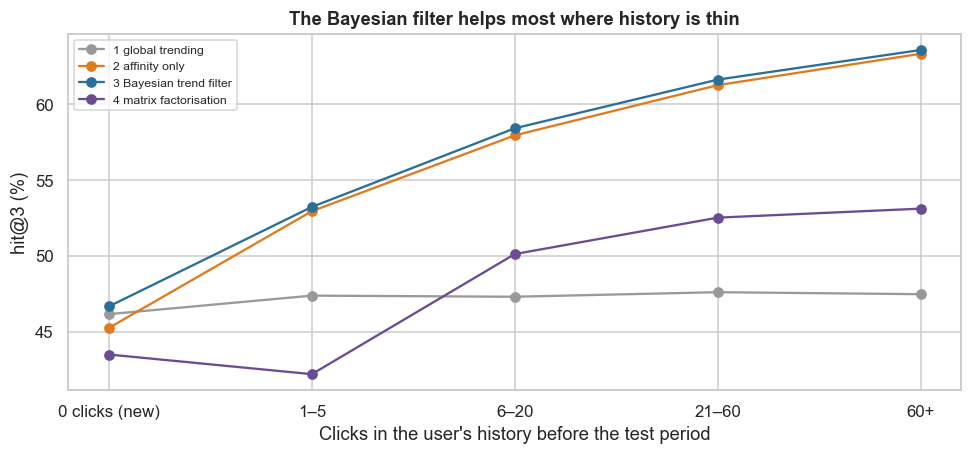

,1 global trending,2 affinity only,3 Bayesian trend filter,4 matrix factorisation,users,Bayes − affinity,Bayes − trending,p (Bayes vs affinity),q_BH
0 clicks (new),0.4615,0.4525,0.4666,0.4349,482,0.0142,0.0051,0.2273,0.2273
1–5,0.4738,0.5295,0.5323,0.4219,8693,0.0028,0.0585,0.1227,0.1534
6–20,0.4730,0.5795,0.5842,0.5012,20367,0.0047,0.1112,0.0000,0.0000
21–60,0.4760,0.6127,0.6163,0.5252,11503,0.0037,0.1403,0.0001,0.0003
60+,0.4747,0.6334,0.6359,0.5312,3213,0.0025,0.1612,0.0454,0.0757


In [9]:
hist_n = cum[:, 41, :].sum(1)
seg = pd.cut(hist_n[per_user.index], [-1, 0, 5, 20, 60, 10 ** 6], labels=["0 clicks (new)", "1–5", "6–20", "21–60", "60+"])
by = per_user.groupby(seg).mean(); by["users"] = per_user.groupby(seg).size()
p_seg = []
for s_ in by.index:
    m = (seg == s_)
    p_seg.append(stats.wilcoxon(per_user.loc[m, "3 Bayesian trend filter"], per_user.loc[m, "2 affinity only"]).pvalue if (per_user.loc[m, "3 Bayesian trend filter"] != per_user.loc[m, "2 affinity only"]).any() else np.nan)
by["Bayes − affinity"] = by["3 Bayesian trend filter"] - by["2 affinity only"]; by["Bayes − trending"] = by["3 Bayesian trend filter"] - by["1 global trending"]
by["p (Bayes vs affinity)"] = p_seg; by["q_BH"] = multipletests(np.nan_to_num(p_seg, nan=1), method="fdr_bh")[1]
fig, ax = plt.subplots(figsize=(9, 4.3))
for m, c_ in zip(METHODS, ["#999", "#e07a1f", "#2a6f97", "#6a4c93"]): ax.plot(by.index.astype(str), by[m] * 100, "o-", color=c_, label=m)
ax.set_xlabel("Clicks in the user's history before the test period"); ax.set_ylabel("hit@3 (%)"); ax.set_title("The Bayesian filter helps most where history is thin"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
by.round(4)

**Takeaway:** for **brand-new users** (0 clicks), nobody can personalise: the Bayesian filter falls back to the trending list (46.7%, vs 45.3% for affinity, which falls back to *usual* popularity). The +1.4 pp difference is not significant (482 users). For users with **6–20, 21–60 and 60+** clicks the filter's edge over affinity is small but significant (+0.25 to +0.47 pp; q ≤ 0.08). The **gap to "trending only" widens with history**, from +0.5 pp (new users) to +16.1 pp (60+ clicks): the more we know, the more personalisation pays. Matrix factorisation is worst for light users (42% for 1–5 clicks), because it needs data to learn factors.

### 7.4 Trend spikes: does the filter react in time?

Festival days are when trend weighting should matter most. We compare daily hit@3 of affinity-only and the Bayesian filter across test days, and test the advantage on **spike days** (Dhanteras gold days 45–47, the second blockbuster weekend 49–51, peak travel days) vs normal days (Mann–Whitney across days). We also compare a **slow trend window** (w = 14 days), which reacts late to spikes.

In [10]:
daily = pd.DataFrame({m: R[m].groupby("day").hit.mean() for m in METHODS}); daily.index = daily.index + 1                    # 1-based day numbers
d1 = []
for d in TEST: d1.append(evaluate(d, scores(d, A_BEST, 14, "3 Bayesian trend filter"))[1].mean())
daily["Bayesian, w = 14 days"] = d1; daily["w=best − w=14 (pp)"] = (daily["3 Bayesian trend filter"] - daily["Bayesian, w = 14 days"]) * 100; daily["Bayes − affinity (pp)"] = (daily["3 Bayesian trend filter"] - daily["2 affinity only"]) * 100
spike = daily.index.isin([45, 46, 47, 49, 50, 51])
mw = stats.mannwhitneyu(daily.loc[spike, "Bayes − affinity (pp)"], daily.loc[~spike, "Bayes − affinity (pp)"], alternative="greater")
print(f"Bayes advantage over affinity: spike days {daily.loc[spike, 'Bayes − affinity (pp)'].mean():+.2f} pp vs normal days {daily.loc[~spike, 'Bayes − affinity (pp)'].mean():+.2f} pp (Mann–Whitney one-sided p = {mw.pvalue:.3f})")
daily.round(4)

Bayes advantage over affinity: spike days +0.61 pp vs normal days +0.15 pp (Mann–Whitney one-sided p = 0.054)


,1 global trending,2 affinity only,3 Bayesian trend filter,4 matrix factorisation,"Bayesian, w = 14 days",w=best − w=14 (pp),Bayes − affinity (pp)
day,,,,,,,
43,0.4794,0.5982,0.6024,0.5158,0.5979,0.4472,0.4237
44,0.4723,0.6060,0.6078,0.5151,0.6046,0.3169,0.1819
45,0.4445,0.5839,0.5924,0.4895,0.5856,0.6783,0.8471
46,0.4446,0.5787,0.5912,0.4813,0.5796,1.1617,1.2522
47,0.4388,0.5807,0.5902,0.4802,0.5820,0.8193,0.9440
48,0.4646,0.5955,0.5979,0.5047,0.5975,0.0467,0.2467
49,0.4487,0.5886,0.5900,0.4983,0.5873,0.2722,0.1439
50,0.4477,0.5944,0.5988,0.4993,0.5973,0.1572,0.4463
51,0.4613,0.6026,0.6030,0.5108,0.6004,0.2612,0.0393


**Observation:** the filter's advantage over affinity peaks exactly on trend days:
- **Dhanteras (days 45–47):** **+0.85, +1.25 and +0.94 pp**.
- **Blockbuster weekend (days 49–51):** smaller gains.
- **Normal days:** around +0.15 pp. The spike-day vs normal-day difference is borderline (Mann–Whitney p = 0.054, only 14 days).
- **On day 52**, just after the spikes end, the filter is *worse* (−0.48 pp): yesterday's trend fades faster than a 1-day window assumes.
- **The 14-day window** reacts too slowly. It loses up to 1.2 pp on Dhanteras vs the 1-day window, while it is close on normal days.

**Business meaning:** the trend term earns its keep during the festival calendar (Diwali, Dhanteras, IPL, big releases), which is also when homepage real estate is most valuable.

### 7.5 Digital-twin A/B: expected top-3 click-through

Offline hit-rates use only what users happened to click. In the simulation we also know each user's **true** click probabilities each day, so we can compute, for every policy, the expected probability that a visit's click falls in the 3 highlighted tiles. That is the quantity an online A/B would measure, without the noise. Paired bootstrap across users; Holm.

In [11]:
aff_true = users_h[[f"_aff_{c}" for c in CATS]].values; r_true = users_h._r.values; T = trend_h[CATS].values
ctr = {m: [] for m in METHODS + ["oracle (true probabilities)"]}; uu = []
for d in TEST:
    act = np.flatnonzero(cnt[:, d, :].sum(1) > 0); P_true = gen.true_probs(aff_true[act], r_true[act], d, T); uu.append(act)
    for m in METHODS:
        S = scores(d, *par[m], m)[act]; top = np.argsort(-S, 1)[:, :3]; ctr[m].append(np.take_along_axis(P_true, top, 1).sum(1))
    ctr["oracle (true probabilities)"].append(np.sort(P_true, 1)[:, -3:].sum(1))
C = {m: np.concatenate(v) for m, v in ctr.items()}
tw = pd.DataFrame({"expected top-3 CTR": {m: C[m].mean() for m in C}})
for m in METHODS:
    dlt = C["3 Bayesian trend filter"] - C[m]; bs = [dlt[RNG.integers(0, len(dlt), len(dlt))].mean() for _ in range(500)]
    tw.loc[m, "Bayes − this (pp)"] = dlt.mean() * 100; tw.loc[m, "CI low"] = np.percentile(bs, 2.5) * 100; tw.loc[m, "CI high"] = np.percentile(bs, 97.5) * 100
tw["share of oracle"] = tw["expected top-3 CTR"] / tw.loc["oracle (true probabilities)", "expected top-3 CTR"]
tw.round(4)

,expected top-3 CTR,Bayes − this (pp),CI low,CI high,share of oracle
1 global trending,0.4748,12.9562,12.8832,13.0257,0.7275
2 affinity only,0.6018,0.2575,0.2396,0.2749,0.9220
3 Bayesian trend filter,0.6044,0.0000,0.0000,0.0000,0.9260
4 matrix factorisation,0.5115,9.2918,9.2289,9.3527,0.7836
oracle (true probabilities),0.6527,NaN,NaN,NaN,1.0000


**Observation:** using the true click probabilities, the expected share of clicks falling in the 3 highlighted tiles is:
- **Bayesian filter:** **60.4%**, which is **93% of the oracle's** 65.3%.
- **Affinity only:** 60.2% (−0.26 pp, CI 0.24–0.27).
- **Matrix factorisation:** 51.2% (−9.3 pp).
- **Global trending:** 47.5% (−13.0 pp).

The twin confirms the offline ranking without day-to-day noise. **The remaining 7% headroom** is mostly users' individual responsiveness to trends, which a single global trend weight cannot capture: the natural next refinement.

## 8. ML Section — "simple beats complex"?

Matrix factorisation (method 4) is the stand-in for a learned recommender. It captures *which categories go together* across users, but has **no notion of time**: it cannot know that today is Dhanteras. The documented formula is a closed form with two interpretable dials (α, w), computable in microseconds per user and explainable to any category head ("we show you gold because you like investments **and** gold is 5× more popular than usual today"). Section 7 measures whether the learned model's extra flexibility is worth it.

## 9. Business Translation — ₹ impact

**Assumptions (D-21-07):**
- 1 crore daily homepage visits.
- 35% of a top-3 tile click converts into a transaction.
- Average take of ₹3 per transaction (convenience fees, MDR and commissions across services).

The value of a policy is its extra expected top-3 clicks vs an alternative.

In [12]:
VISITS, CONV, TAKE = 1e7, 0.35, 3.0
money = pd.DataFrame({"extra tile clicks per day (lakh)": (tw.loc["3 Bayesian trend filter", "expected top-3 CTR"] - tw["expected top-3 CTR"]) * VISITS / 1e5})
money["₹ crore per year"] = money.iloc[:, 0] * 1e5 * CONV * TAKE * 365 / 1e7
head = -money.loc["oracle (true probabilities)"]; money = money.drop(index=["3 Bayesian trend filter", "oracle (true probabilities)"]); money.index = ["Bayes vs " + i for i in money.index]
print(f"Headroom: a perfect (oracle) ranking would add {head.iloc[0]:.2f} lakh tile clicks/day ≈ ₹{head.iloc[1]:.1f} crore/year more than the Bayesian filter")
money.round(3)

Headroom: a perfect (oracle) ranking would add 4.83 lakh tile clicks/day ≈ ₹18.5 crore/year more than the Bayesian filter


,extra tile clicks per day (lakh),₹ crore per year
Bayes vs 1 global trending,12.9560,49.6550
Bayes vs 2 affinity only,0.2570,0.9870
Bayes vs 4 matrix factorisation,9.2920,35.6110


**Takeaway (business reading):** at **1 crore homepage visits a day** (assumptions: 35% of tile clicks lead to a transaction; ₹3 average take):
- **vs a non-personalised "trending" homepage:** ≈ **+13 lakh tile clicks/day ≈ ₹50 crore/year**.
- **vs the matrix-factorisation recommender:** ≈ +9.3 lakh clicks/day ≈ **₹36 crore/year**.
- **vs habits alone:** ≈ +0.26 lakh clicks/day ≈ **₹1 crore/year**, concentrated in festival weeks.
- **Headroom:** a perfect ranking would add ≈ ₹18.5 crore/year more. That is the most a fancier model could ever win here.
- **Reading:** personalisation itself is worth tens of crores. The trend term is a cheap seasonal top-up. Complexity is not automatically value.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** Bayes beats affinity (+0.40 pp, p < 0.0001), but the effect is small.
- **H2 ✅:** Bayes beats global trending (+11.1 pp).
- **H3 ✅:** Bayes beats matrix factorisation (+9.2 pp).
- **Twin:** 93% of the oracle.

**I recommend:**
1. **Ship the Bayesian trend filter as the homepage baseline** (α ≈ 10 pseudo-clicks, re-estimated monthly by empirical Bayes; 1-day trend window from **organic** clicks, excluding promoted tiles and bots).
2. **Keep a 5% random-exploration slot,** so trend estimates are not driven by what the homepage itself promotes.
3. **Next refinement:** a per-user trend exponent (some users ignore trends), and decay faster after spikes (the day-52 dip).
4. **Gate complex models:** any recommender must beat this baseline in a live A/B on transactions, not just clicks, before replacing it. Use Case 20's propensity × LTV logic for the money metric.
5. **Monitoring:** daily bot and logging-gap checks *before* computing trends (as §5 showed, a bot can hide a data outage).

**KPIs:** top-3 tile CTR and transactions per visit (vs holdout); hit@3 by user-history segment; festival-day lift; share of homepage impressions from exploration; data-quality alerts (bots, gaps).

## 11. Risks, Limitations and Next Steps

- **Synthetic tastes and trends:** the simulation fixes the "true" model (affinity × trend^r), which is close to the documented formula's assumptions and so favours it. Real users have cross-category patterns (e.g., flights → hotels) where learned models can add value. **The live A/B is the real test.**
- **Inventory and business rules:** the documented system also balances banner/icon inventory proportions and commercial commitments. Those constraints sit on top of the score (e.g., guaranteed slots for paid campaigns) and reduce the achievable gain.
- **Feedback loops:** showing trending tiles makes them more clicked, which feeds the trend. Keep a small random-exploration slot and compute trends from **organic** (non-promoted) clicks.
- **Responsiveness differs:** some users never follow trends. A per-user exponent (score = P(c∣u) × (P_now/P_usual)^r̂ᵤ) is the natural next refinement.
- **Measure the right outcome:** clicks are a proxy. The business metric is transactions and their margin (see Case 20 for propensity × LTV ranking).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Documented Bayesian update | p_next(c ∣ u) ∝ p(c ∣ u) · p_now(c) / p_usual(c) |
| Dirichlet smoothing | p(c ∣ u) = (n_uc + α·p_usual(c)) / (n_u + α) |
| Dirichlet–multinomial marginal likelihood | Σ_u [ln Γ(α) − ln Γ(n_u + α) + Σ_c (ln Γ(n_uc + α p_c) − ln Γ(α p_c))] |
| hit@3 | clicks on the top-3 categories / all clicks |
| NDCG@3 | Σ_clicked 1/log₂(rank + 1) for ranks ≤ 3, divided by the ideal |
| MRR | mean of 1/rank of clicked categories |
| Matched-pairs rank-biserial | (ΣR⁺ − ΣR⁻)/ΣR |

| Term | Meaning |
|---|---|
| Affinity | A user's own preference over categories |
| Trend | How much more (or less) popular a category is now than usual |
| Cold start | Users with little or no history |
| Empirical Bayes | Estimating the prior's strength from the data themselves |
| Matrix factorisation | A learned model that compresses the user × category matrix into a few factors |
| Digital twin | A simulation in which the true click probabilities are known |